In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/krishnaik06/Complete-Machine-Learning-2023/main/Algerian_forest_fires_dataset_UPDATE.csv"
    ,header=1)
df

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,01,06,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire
1,02,06,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire
2,03,06,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire
3,04,06,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire
4,05,06,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,26,09,2012,30,65,14,0,85.4,16,44.5,4.5,16.9,6.5,fire
242,27,09,2012,28,87,15,4.4,41.1,6.5,8,0.1,6.2,0,not fire
243,28,09,2012,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire
244,29,09,2012,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire


In [ ]:
df.shape

(246, 14)

In [ ]:
df.isnull().sum()

,0
day,0
month,1
year,1
Temperature,1
RH,1
Ws,1
Rain,1
FFMC,1
DMC,1
DC,1


In [ ]:
df.isnull().any()

,0
day,False
month,True
year,True
Temperature,True
RH,True
Ws,True
Rain,True
FFMC,True
DMC,True
DC,True


In [ ]:
df[df.isnull().any(axis=1)]

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
122,Sidi-Bel Abbes Region Dataset,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
167,14,07,2012,37,37,18,0.2,88.9,12.9,14.6 9,12.5,10.4,fire,NaN


In [ ]:
df.loc[:122,'Region'] = 0 # Bejaia Region
df.loc[122:,'Region'] = 1 # Sidi-Bel Abbes

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246 entries, 0 to 245
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          246 non-null    object 
 1   month        245 non-null    object 
 2   year         245 non-null    object 
 3   Temperature  245 non-null    object 
 4    RH          245 non-null    object 
 5    Ws          245 non-null    object 
 6   Rain         245 non-null    object 
 7   FFMC         245 non-null    object 
 8   DMC          245 non-null    object 
 9   DC           245 non-null    object 
 10  ISI          245 non-null    object 
 11  BUI          245 non-null    object 
 12  FWI          245 non-null    object 
 13  Classes      244 non-null    object 
 14  Region       246 non-null    float64
dtypes: float64(1), object(14)
memory usage: 29.0+ KB


In [ ]:
df[['Region']] = df[['Region']].astype(int)

In [ ]:
df[df.isnull().any(axis=1)]

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
122,Sidi-Bel Abbes Region Dataset,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
167,14,07,2012,37,37,18,0.2,88.9,12.9,14.6 9,12.5,10.4,fire,NaN,1


In [ ]:
df.iloc[[122]]

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
122,Sidi-Bel Abbes Region Dataset,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


In [ ]:
df = df.dropna().reset_index(drop=True)
df.shape

(244, 15)

In [ ]:
df = df.drop(df.index[122]).reset_index(drop=True)
df.shape

(243, 15)

In [ ]:
df.columns

Index(['day', 'month', 'year', 'Temperature', ' RH', ' Ws', 'Rain ', 'FFMC',
       'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes  ', 'Region'],
      dtype='object')

In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,01,06,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,02,06,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,0
2,03,06,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,04,06,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire,0
4,05,06,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire,0


In [ ]:
df[['month','day','year','Temperature','RH','Ws']] = df[['month','day','year','Temperature','RH','Ws']].astype(int)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   day          243 non-null    int64 
 1   month        243 non-null    int64 
 2   year         243 non-null    int64 
 3   Temperature  243 non-null    int64 
 4   RH           243 non-null    int64 
 5   Ws           243 non-null    int64 
 6   Rain         243 non-null    object
 7   FFMC         243 non-null    object
 8   DMC          243 non-null    object
 9   DC           243 non-null    object
 10  ISI          243 non-null    object
 11  BUI          243 non-null    object
 12  FWI          243 non-null    object
 13  Classes      243 non-null    object
 14  Region       243 non-null    int64 
dtypes: int64(7), object(8)
memory usage: 28.6+ KB


In [ ]:
objects = [feature for feature in df.columns if df[feature].dtype == 'O']
objects

['Rain', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes']

In [ ]:
for i in objects:
  if i!= 'Classes':
      df[i] = df[i].astype(float)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          243 non-null    int64  
 1   month        243 non-null    int64  
 2   year         243 non-null    int64  
 3   Temperature  243 non-null    int64  
 4   RH           243 non-null    int64  
 5   Ws           243 non-null    int64  
 6   Rain         243 non-null    float64
 7   FFMC         243 non-null    float64
 8   DMC          243 non-null    float64
 9   DC           243 non-null    float64
 10  ISI          243 non-null    float64
 11  BUI          243 non-null    float64
 12  FWI          243 non-null    float64
 13  Classes      243 non-null    object 
 14  Region       243 non-null    int64  
dtypes: float64(7), int64(7), object(1)
memory usage: 28.6+ KB


In [ ]:
df_copy = df.copy()
df_copy

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
238,26,9,2012,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,6.5,fire,1
239,27,9,2012,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0.0,not fire,1
240,28,9,2012,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire,1
241,29,9,2012,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire,1


**Exploratory Data Analysis**

In [ ]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [ ]:
df.drop(columns=['day','month','year'],inplace=True)
df

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0
...,...,...,...,...,...,...,...,...,...,...,...,...
238,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,6.5,fire,1
239,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0.0,not fire,1
240,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire,1
241,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire,1


In [ ]:
df['Classes'].value_counts() # problem in encoding

,count
Classes,
fire,131
not fire,101
fire,4
fire,2
not fire,2
not fire,1
not fire,1
not fire,1


In [ ]:
# Encoding categories in classes

# df['Classes'] = np.where(df['Classes'] == 'not fire',0,1)
df['Classes'] = np.where(df['Classes'].str.contains('not fire'),0,1)

In [ ]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0


In [ ]:
df['Classes'].value_counts()

,count
Classes,
1,137
0,106


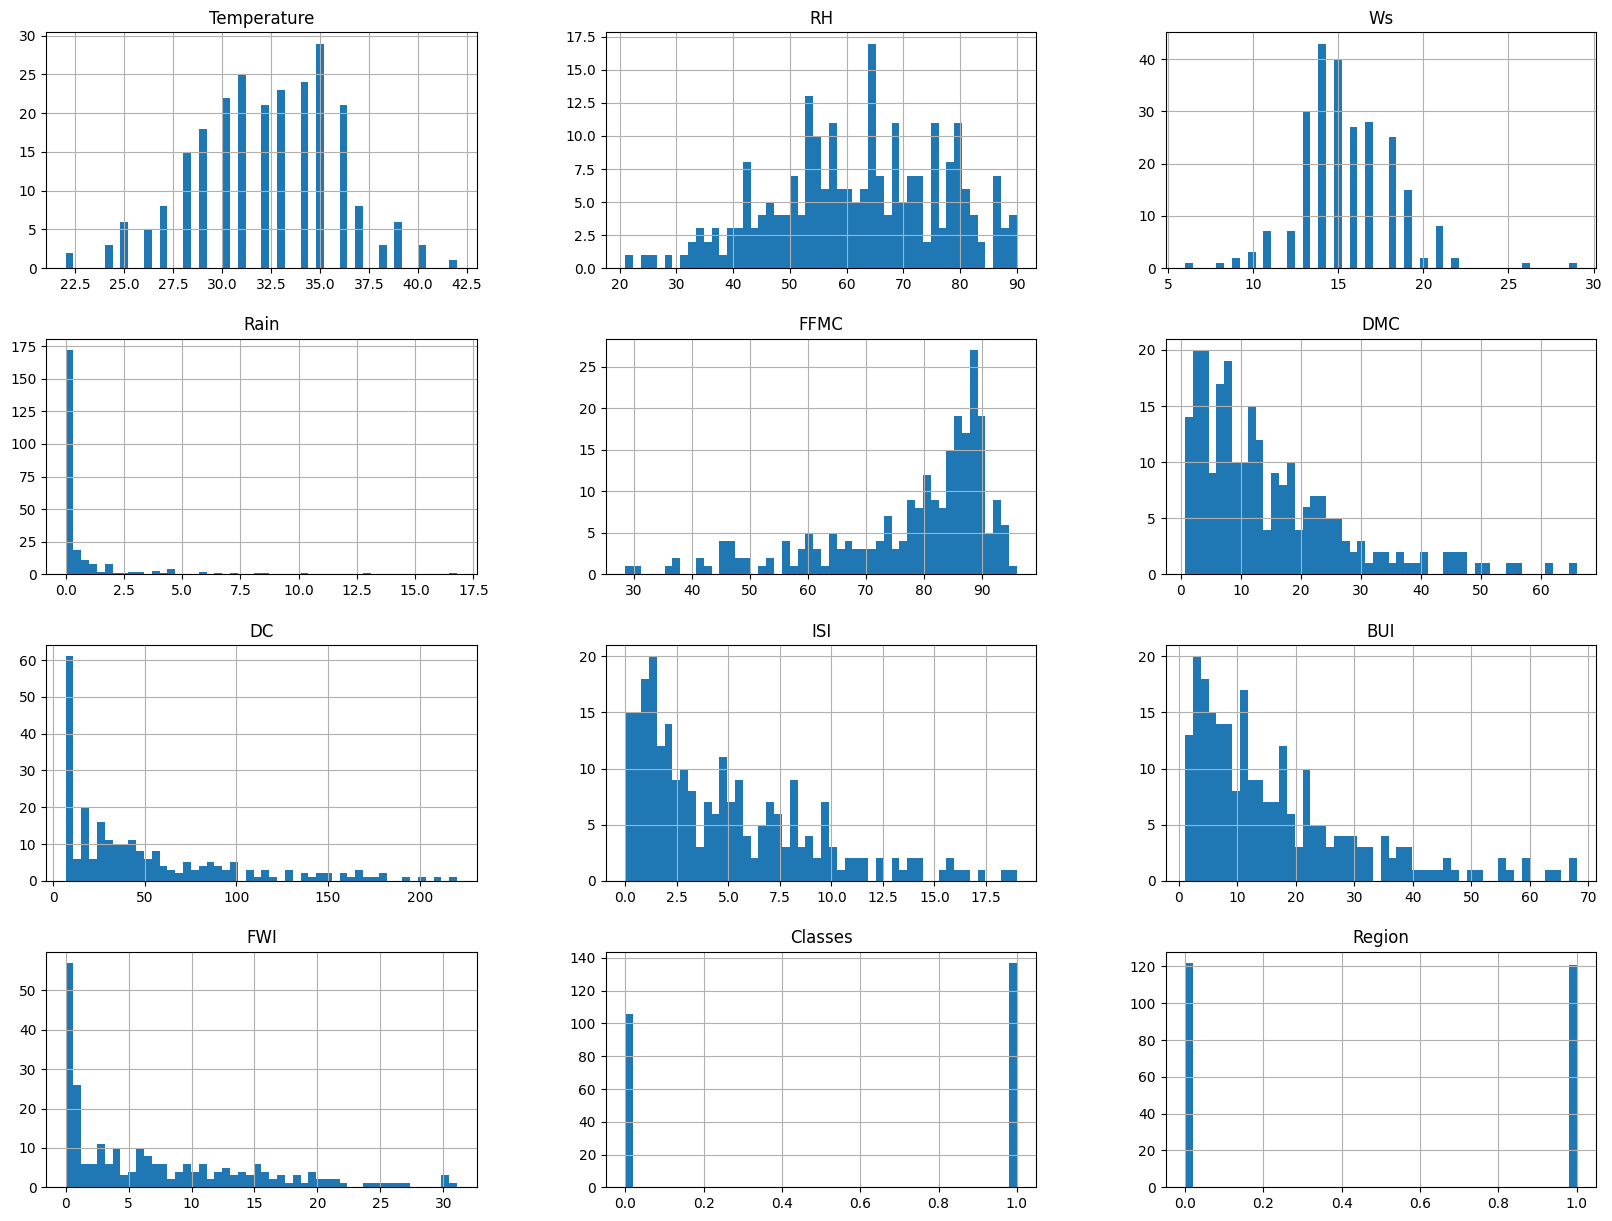

In [ ]:
df.hist(bins=50,figsize=(20,15)) # slice entire range into 50 equal-sized buckets & count how many datapoints in eac bucket
plt.show()

In [ ]:
# percentage for pie chart
percentages = df['Classes'].value_counts(normalize=True)*100
percentages

,proportion
Classes,
1,56.378601
0,43.621399


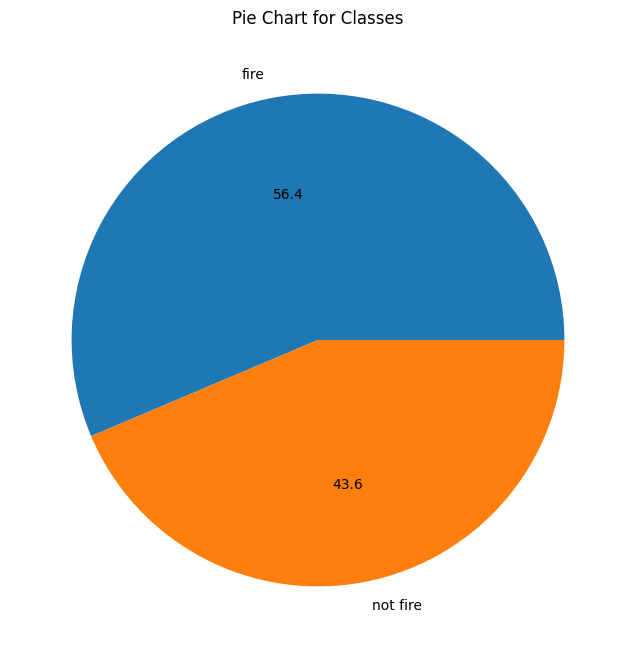

In [ ]:
# plotting a piechart

plt.figure(figsize=(12,8))
plt.pie(percentages,labels=['fire','not fire'],autopct='%1.1f')
plt.title('Pie Chart for Classes')
plt.show()

In [ ]:
# Correlation
df.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
Temperature,1.000000,-0.651400,-0.284510,-0.326492,0.676568,0.485687,0.376284,0.603871,0.459789,0.566670,0.516015,0.269555
RH,-0.651400,1.000000,0.244048,0.222356,-0.644873,-0.408519,-0.226941,-0.686667,-0.353841,-0.580957,-0.432161,-0.402682
Ws,-0.284510,0.244048,1.000000,0.171506,-0.166548,-0.000721,0.079135,0.008532,0.031438,0.032368,-0.069964,-0.181160
Rain,-0.326492,0.222356,0.171506,1.000000,-0.543906,-0.288773,-0.298023,-0.347484,-0.299852,-0.324422,-0.379097,-0.040013
FFMC,0.676568,-0.644873,-0.166548,-0.543906,1.000000,0.603608,0.507397,0.740007,0.592011,0.691132,0.769492,0.222241
DMC,0.485687,-0.408519,-0.000721,-0.288773,0.603608,1.000000,0.875925,0.680454,0.982248,0.875864,0.585658,0.192089
DC,0.376284,-0.226941,0.079135,-0.298023,0.507397,0.875925,1.000000,0.508643,0.941988,0.739521,0.511123,-0.078734
ISI,0.603871,-0.686667,0.008532,-0.347484,0.740007,0.680454,0.508643,1.000000,0.644093,0.922895,0.735197,0.263197
BUI,0.459789,-0.353841,0.031438,-0.299852,0.592011,0.982248,0.941988,0.644093,1.000000,0.857973,0.586639,0.089408
FWI,0.566670,-0.580957,0.032368,-0.324422,0.691132,0.875864,0.739521,0.922895,0.857973,1.000000,0.719216,0.197102


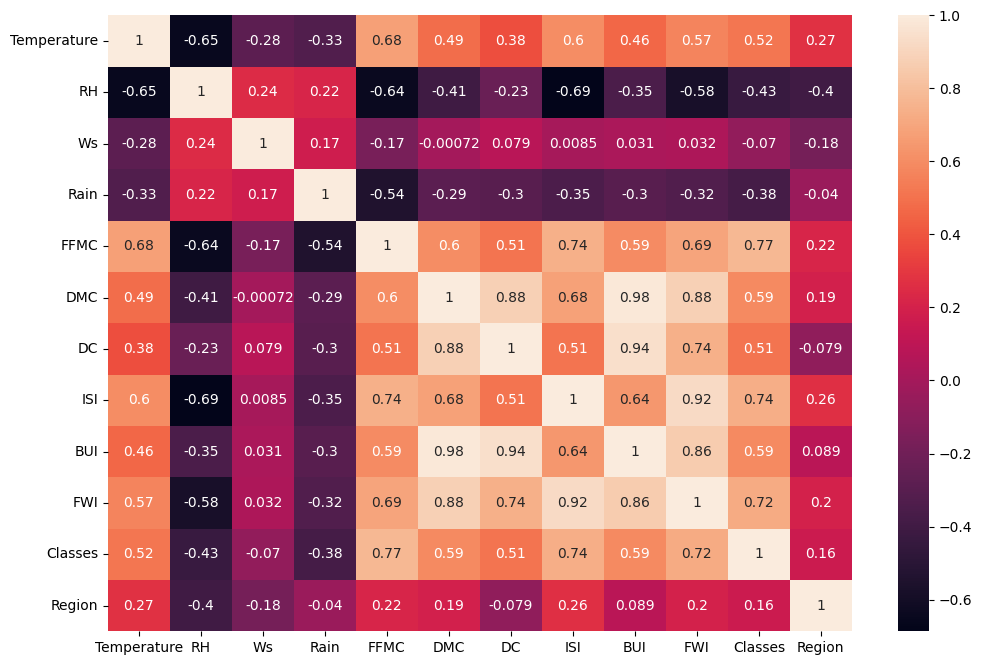

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True)
plt.show()

<Axes: ylabel='FWI'>

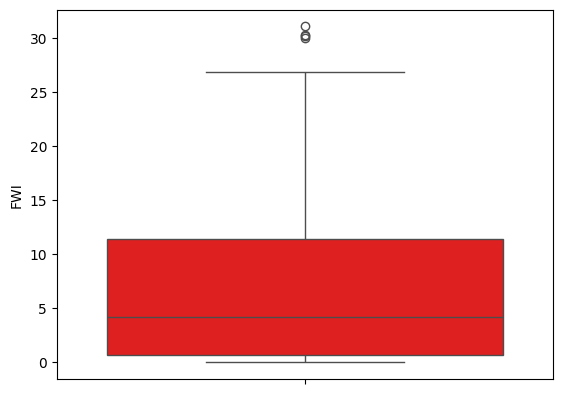

In [ ]:
sns.boxplot(df['FWI'],color='red')

In [ ]:
# monthly fire analysis
df.loc[df['Region']==1]
# sns.countplot(x='month',hue='Classes',data=df)

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
122,32,71,12,0.7,57.1,2.5,8.2,0.6,2.8,0.2,0,1
123,30,73,13,4.0,55.7,2.7,7.8,0.6,2.9,0.2,0,1
124,29,80,14,2.0,48.7,2.2,7.6,0.3,2.6,0.1,0,1
125,30,64,14,0.0,79.4,5.2,15.4,2.2,5.6,1.0,0,1
126,32,60,14,0.2,77.1,6.0,17.6,1.8,6.5,0.9,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
238,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,6.5,1,1
239,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0.0,0,1
240,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,0,1
241,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,0,1


***Feature Engineering***

In [ ]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0


In [ ]:
df.tail()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
238,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,6.5,1,1
239,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0.0,0,1
240,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,0,1
241,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,0,1
242,24,64,15,0.2,67.3,3.8,16.5,1.2,4.8,0.5,0,1


In [ ]:
# Independent and Dependent features

X = df.drop('FWI',axis=1)
y = df['FWI']

In [ ]:
X

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0,0
...,...,...,...,...,...,...,...,...,...,...,...
238,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,1,1
239,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0,1
240,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0,1
241,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0,1


In [ ]:
y

,FWI
0,0.5
1,0.4
2,0.1
3,0.0
4,0.5
...,...
238,6.5
239,0.0
240,0.2
241,0.7


In [ ]:
# Train-Test

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25,random_state=7)

In [ ]:
X_train.shape,X_test.shape

((182, 11), (61, 11))

In [ ]:
# Check for multicollinearity using heatmap
# threshold is set by domain expertise

def correlation(dataset,threshold):
  correlated_columns = set()
  corr_matrix = dataset.corr()

  for i in range(len(corr_matrix.columns)):
    for j in range(i):
      if abs(corr_matrix.iloc[i,j]) > threshold:
        correlated_columns.add(corr_matrix.columns[i])

  return correlated_columns

In [ ]:
corr_features = correlation(X_train,0.85)
corr_features

{'BUI', 'DC'}

In [ ]:
## drop corrrelated features
X_train.drop(corr_features,axis=1,inplace=True)
X_test.drop(corr_features,axis=1,inplace=True)

In [ ]:
X_train.shape,X_test.shape

((182, 9), (61, 9))

**Feature Scaling OR Standadization**

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
X_train_scaled,X_test_scaled

(array([[-1.47439426,  0.88104171,  1.31829252, ..., -0.90852102,
         -1.06825862, -1.04496604],
        [-0.91360062,  0.21624241,  1.31829252, ..., -0.74255374,
         -1.06825862, -1.04496604],
        [ 0.76878029, -0.44855689, -0.48027749, ...,  0.65631329,
          0.93610291, -1.04496604],
        ...,
        [-0.35280699,  0.14976248,  0.95857852, ...,  0.49034601,
          0.93610291, -1.04496604],
        [ 0.76878029, -1.04687626, -0.83999149, ..., -0.26836153,
          0.93610291,  0.9569689 ],
        [ 1.89036756,  0.14976248, -2.2788475 , ..., -0.83739218,
         -1.06825862,  0.9569689 ]]),
 array([[ 0.76878029,  0.4156822 ,  1.31829252, -0.38994339,  0.75899377,
          1.06005863,  0.98824784,  0.93610291, -1.04496604],
        [-1.19399744, -0.71447661,  0.59886452,  0.24853831, -0.44368154,
         -0.57175576, -0.74255374, -1.06825862,  0.9569689 ],
        [-2.0351879 ,  1.81176073, -0.83999149,  0.83790605, -3.48951014,
         -1.1455806 , -1.09

**Box Plots To Understand Effects of Scaling**

Text(0.5, 1.0, 'X_train after scaling')

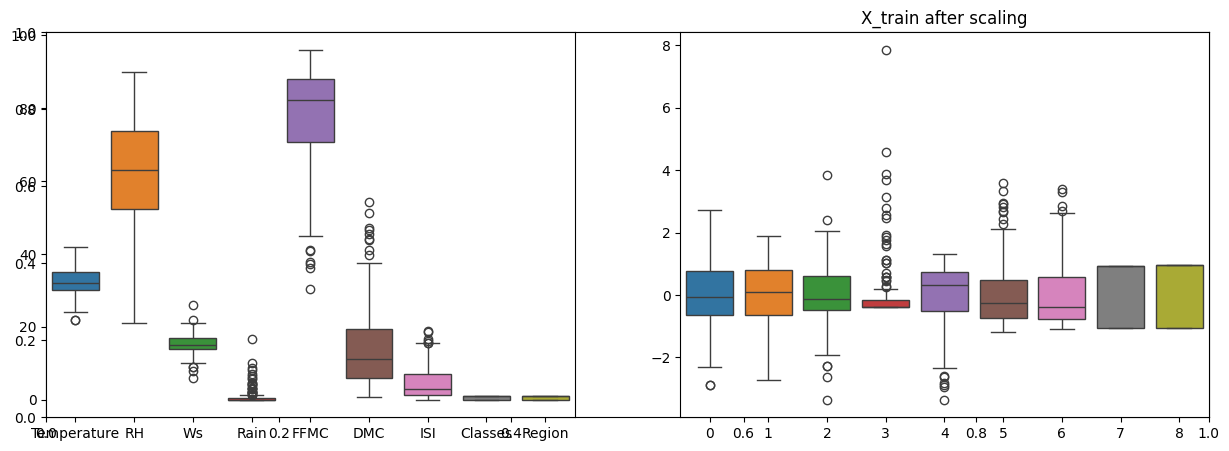

In [ ]:
plt.subplots(figsize=(15,5))
plt.subplot(1,2,1)
sns.boxplot(data=X_train)
plt.subplot(1,2,2)
sns.boxplot(data=X_train_scaled)

plt.title('X_train after scaling')

**Linear Regression Model**

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error

linreg = LinearRegression()
linreg.fit(X_train_scaled,y_train)

y_pred = linreg.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print('MAE:',mae)
print('R2 Score:',r2)

MAE: 0.765230824761701
R2 Score: 0.9830442748123898


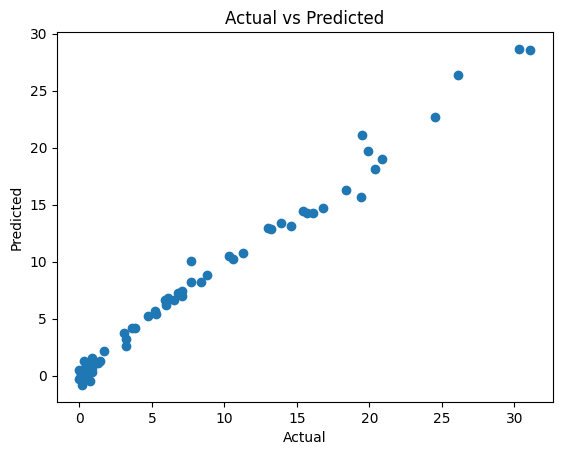

In [ ]:
plt.scatter(y_test,y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.show()

**Lasso Regression (L1 Regularization)**

MAE: 1.5085737284720477
R2 Score: 0.9312816543178953


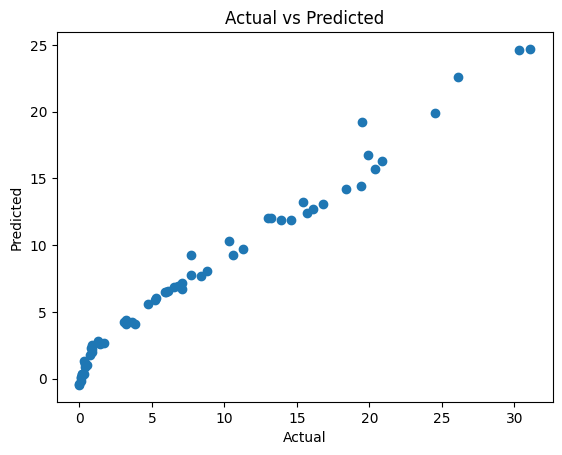

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score,mean_absolute_error

lasso = Lasso()
lasso.fit(X_train_scaled,y_train)

y_pred = lasso.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print('MAE:',mae)
print('R2 Score:',r2)

plt.scatter(y_test,y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.show()

In [ ]:
from sklearn.linear_model import LassoCV

lassocv = LassoCV(cv=5)
lassocv.fit(X_train_scaled,y_train)

LassoCV(cv=5)

In [ ]:
y_pred = lassocv.predict(X_test_scaled)

In [ ]:
lassocv.alpha_

np.float64(0.026496607694277523)

In [ ]:
lassocv.alphas_,len(lassocv.alphas_)

(array([6.56341204, 6.12106004, 5.70852108, 5.32378586, 4.96498051,
        4.63035744, 4.31828685, 4.02724877, 3.75582568, 3.5026956 ,
        3.26662564, 3.04646601, 2.84114439, 2.64966077, 2.4710825 ,
        2.30453981, 2.14922154, 2.0043712 , 1.86928329, 1.74329985,
        1.62580728, 1.51623331, 1.41404426, 1.31874241, 1.22986358,
        1.14697489, 1.06967263, 0.99758027, 0.9303467 , 0.86764445,
        0.80916811, 0.75463289, 0.70377316, 0.6563412 , 0.612106  ,
        0.57085211, 0.53237859, 0.49649805, 0.46303574, 0.43182869,
        0.40272488, 0.37558257, 0.35026956, 0.32666256, 0.3046466 ,
        0.28411444, 0.26496608, 0.24710825, 0.23045398, 0.21492215,
        0.20043712, 0.18692833, 0.17432999, 0.16258073, 0.15162333,
        0.14140443, 0.13187424, 0.12298636, 0.11469749, 0.10696726,
        0.09975803, 0.09303467, 0.08676444, 0.08091681, 0.07546329,
        0.07037732, 0.06563412, 0.0612106 , 0.05708521, 0.05323786,
        0.04964981, 0.04630357, 0.04318287, 0.04

In [ ]:
lassocv.mse_path_,len(lassocv.mse_path_)

(array([[49.40422413, 36.79100337, 65.68739914, 36.50117423, 56.72598273],
        [43.87830678, 32.24908599, 65.04706371, 31.93813558, 52.06072772],
        [39.05044313, 28.3272454 , 58.36667746, 28.08098057, 46.76825661],
        [34.83117367, 24.94279601, 52.48289363, 24.83024951, 42.13306019],
        [30.98967973, 21.63175478, 47.29690925, 22.07935167, 38.07168952],
        [27.21683227, 18.75971341, 42.72245659, 19.26566922, 34.31201176],
        [23.92997491, 16.27376121, 38.25680203, 16.86742483, 30.50300947],
        [21.06609935, 14.12280241, 33.7684143 , 14.82710303, 27.16160406],
        [18.57027631, 12.26230288, 29.84216032, 13.09501414, 24.22866139],
        [16.39525827, 10.65402041, 26.40610629, 11.62814757, 21.65278214],
        [14.49937332,  9.26429947, 23.39849475, 10.38928786, 19.38914037],
        [12.84654469,  8.06406006, 20.76448822,  9.3459665 , 17.39830882],
        [11.40537587,  7.02805124, 18.45664664,  8.47094504, 15.64686299],
        [10.14854212,  6.

Mean Absolute Error:  0.7628110212164096
R2 Score:  0.9824865181011864


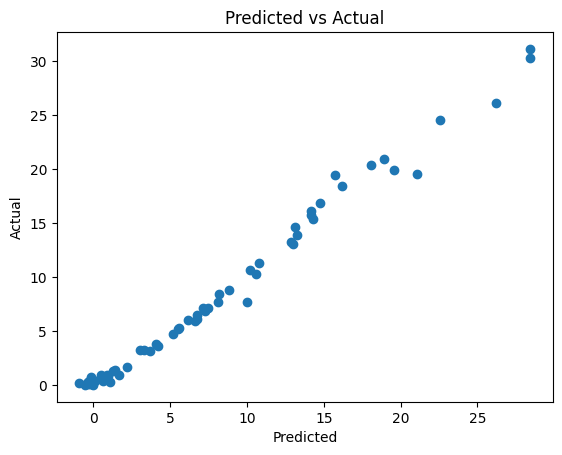

In [ ]:
plt.scatter(y_pred,y_test)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Predicted vs Actual')

print("Mean Absolute Error: ",mean_absolute_error(y_test,y_pred))
print("R2 Score: ",r2_score(y_test,y_pred))

**Ridge Regression(L2 Regularization)**

MAE: 0.781251475863559
R2 Score: 0.9824042844794716


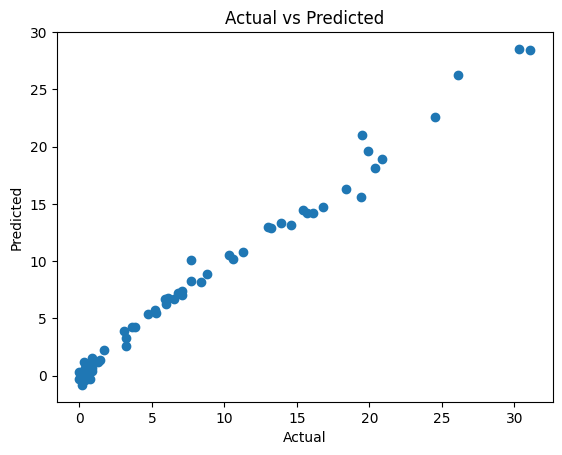

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score,mean_absolute_error

ridge = Ridge()
ridge.fit(X_train_scaled,y_train)

y_pred = ridge.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print('MAE:',mae)
print('R2 Score:',r2)

plt.scatter(y_test,y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.show()

MAE: 0.781251475863559
R2 Score: 0.9824042844794716


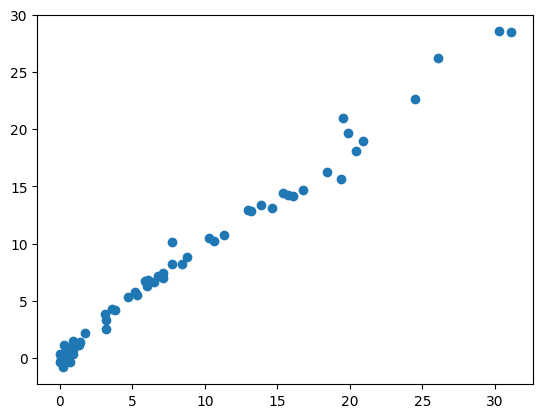

In [ ]:
from sklearn.linear_model import RidgeCV

ridgecv = RidgeCV(cv=5)
ridgecv.fit(X_train_scaled,y_train)

y_pred = ridgecv.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print('MAE:',mae)
print('R2 Score:',r2)
plt.scatter(y_test,y_pred)

In [ ]:
ridgecv.alpha_

np.float64(1.0)

In [ ]:
ridgecv.alphas

(0.1, 1.0, 10.0)

In [ ]:
ridgecv.get_params()

{'alpha_per_target': False,
 'alphas': (0.1, 1.0, 10.0),
 'cv': 5,
 'fit_intercept': True,
 'gcv_mode': None,
 'scoring': None,
 'store_cv_results': None,
 'store_cv_values': 'deprecated'}

**ElasticNet**

MAE: 2.2680354092792836
R2 Score: 0.8585725645845957


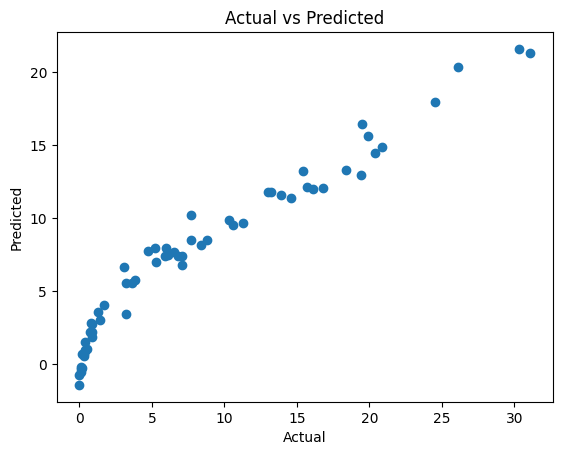

In [ ]:
from sklearn.linear_model import ElasticNet
from sklearn.metrics import r2_score,mean_absolute_error

elastic = ElasticNet()
elastic.fit(X_train_scaled,y_train)

y_pred = elastic.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print('MAE:',mae)
print('R2 Score:',r2)

plt.scatter(y_test,y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.show()

In [ ]:
from sklearn.linear_model import ElasticNetCV

elasticcv = ElasticNetCV(cv=5)
elasticcv.fit(X_train_scaled,y_train)

ElasticNetCV(cv=5)

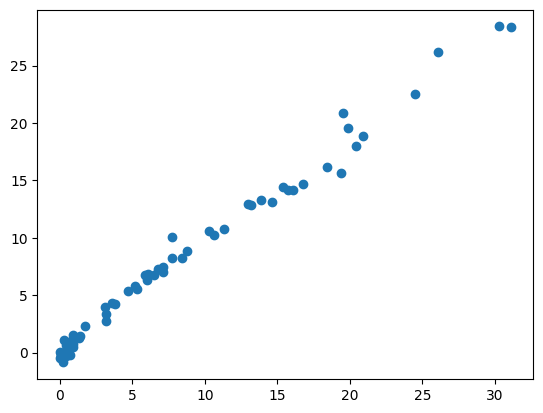

In [ ]:
y_pred = elasticcv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)

In [ ]:
# pickling ML model,preprocessing model standard
import pickle

pickle.dump(scaler,open('scaler.pkl','wb'))
pickle.dump(ridge,open('ridge.pkl','wb'))